# **Project Name**    - FBI Crime Investigation – Monthly Crime Incident Forecasting



##### **Project Type**    - Time-Series Forecasting / Regression
##### **Contribution**    - Individual
##### **Name**            - Vrushali Phaltane


# **Project Summary -**


Crime analysis plays an important role in supporting public safety planning, resource allocation, patrol scheduling, and identification of recurring crime patterns. This project focuses on analyzing historical crime incident data and forecasting the expected number of crime incidents on a monthly basis. The objective is to identify temporal patterns and develop a machine learning-based forecasting solution that can support data-driven operational planning.

The dataset contains approximately 474,565 crime incident records covering the period from 1999 to 2011. The major variables include crime type, location information, neighborhood, geographic coordinates, hour, minute, year, month, day, and incident date. The raw incident-level data was cleaned and transformed into a monthly time-series dataset by aggregating individual incidents into total monthly crime counts. This resulted in 156 monthly observations from January 1999 to December 2011.

Exploratory Data Analysis was performed to understand overall crime trends, monthly seasonality, crime-type distributions, temporal patterns, relationships between variables, and correlations among engineered forecasting features. Multiple visualizations were created using univariate, bivariate, and multivariate analysis techniques. The analysis identified recurring seasonal patterns and demonstrated that historical crime counts contain useful information for forecasting future monthly crime volume.

Feature engineering was performed specifically for the time-series forecasting problem. Lag features such as one-month, two-month, three-month, six-month, and twelve-month historical values were created. Rolling mean features over three, six, and twelve months were also generated to capture short-term and long-term trends. Calendar features such as month and year were included to capture seasonal and temporal effects. Correlation analysis showed high relationships among several lag and rolling features; however, these relationships were expected because the features were derived from the same historical time series. Since XGBoost is a tree-based algorithm, the features were retained based on their forecasting usefulness and validation performance.

Three forecasting approaches were evaluated: Seasonal Naive, SARIMA, and XGBoost. The Seasonal Naive model was used as a baseline, while SARIMA was used as a classical statistical time-series model. XGBoost was implemented using engineered lag, rolling-average, month, and year features. The data was divided chronologically, with January 1999 to December 2010 used for training and January 2011 to December 2011 used as the validation period. This chronological approach prevents future information from being used during model training.

Among the evaluated models, XGBoost achieved the best validation performance, with an MAE of 153.04, RMSE of 190.83, MAPE of 5.12%, and R² of 0.6130 on the 2011 validation period. The final XGBoost model was subsequently trained using the complete historical dataset through December 2011 and used to generate recursive forecasts for January–December 2012.

Feature importance analysis showed that the twelve-month rolling mean, twelve-month lag, one-month lag, and year were among the most influential features. The 2012 forecast indicates relatively lower predicted crime volume around February, increasing toward the middle of the year, with the highest predicted monthly value occurring around August.

The resulting solution can serve as a decision-support system for understanding historical crime patterns, anticipating expected monthly crime volume, and supporting resource and operational planning. However, the forecasts represent aggregate crime counts and should not be interpreted as predictions of individual crimes or offenders. Since actual 2012 observations are unavailable in the dataset, the 2012 forecast could not be directly evaluated against actual values.


# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


**# Problem Statement

Crime departments and public safety organizations need reliable information about historical and expected crime patterns to support effective resource allocation and operational planning. However, large volumes of incident-level crime records can make it difficult to identify long-term trends, recurring seasonal patterns, and expected future crime volumes manually.

The objective of this project is to analyze historical crime incident data from 1999 to 2011, identify important temporal and seasonal patterns, and develop a forecasting model capable of predicting monthly crime incident counts.

The project aggregates incident-level records into monthly crime counts and evaluates multiple forecasting approaches, including Seasonal Naive, SARIMA, and XGBoost. Time-series features such as historical lag values, rolling averages, month, and year are engineered to capture short-term, seasonal, and long-term patterns.

The final objective is to select the best-performing model based on appropriate forecasting evaluation metrics and use it to forecast monthly crime incident counts for 2012. The resulting forecasts can provide decision support for resource planning, patrol scheduling, operational preparation, and monitoring of expected crime trends.

The model is intended as a decision-support tool and does not predict individual offenders or individual future crimes.
.**

### Import Libraries

In [28]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn statsmodels xgboost joblib openpyxl


In [29]:
import sys

print("Python:", sys.version)

import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
import statsmodels
import xgboost
import joblib

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Statsmodels:", statsmodels.__version__)
print("XGBoost:", xgboost.__version__)

print("\nAll libraries imported successfully!")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
Statsmodels: 0.15.0
XGBoost: 3.4.1

All libraries imported successfully!


### Dataset Loading

In [30]:
from google.colab import files

uploaded = files.upload()

Saving Train.xlsx to Train (1).xlsx


In [31]:
from google.colab import files

uploaded = files.upload()

Saving Test.csv to Test (1).csv


In [32]:
import os

os.listdir('/content')


['.config',
 'Test.csv',
 'Test (1).csv',
 'Train.xlsx',
 'Train (1).xlsx',
 'sample_data']

### Dataset First View

In [33]:
import pandas as pd

train_df = pd.read_excel('/content/Train.xlsx')
test_df = pd.read_csv('/content/Test.csv')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

Train shape: (474565, 13)
Test shape: (162, 4)

Train columns:
['TYPE', 'HUNDRED_BLOCK', 'NEIGHBOURHOOD', 'X', 'Y', 'Latitude', 'Longitude', 'HOUR', 'MINUTE', 'YEAR', 'MONTH', 'DAY', 'Date']

Test columns:
['YEAR', 'MONTH', 'TYPE', 'Incident_Counts']


###Dataset displaying first 10 rows

In [34]:
display(train_df.head(10))
display(test_df.head(10))

,TYPE,HUNDRED_BLOCK,NEIGHBOURHOOD,X,Y,Latitude,Longitude,HOUR,MINUTE,YEAR,MONTH,DAY,Date
0,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,16.0,15.0,1999,5,12,1999-05-12
1,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,15.0,20.0,1999,5,7,1999-05-07
2,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,16.0,40.0,1999,4,23,1999-04-23
3,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,11.0,15.0,1999,4,20,1999-04-20
4,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,17.0,45.0,1999,4,12,1999-04-12
5,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,20.0,45.0,1999,3,26,1999-03-26
6,Break and Enter Residential/Other,63XX WILTSHIRE ST,Kerrisdale,489325.58,5452817.95,49.228051,-123.146610,12.0,0.0,1999,3,10,1999-03-10
7,Mischief,40XX W 19TH AVE,Dunbar-Southlands,485903.09,5455883.77,49.255559,-123.193725,4.0,13.0,1999,6,28,1999-06-28
8,Other Theft,9XX TERMINAL AVE,Strathcona,493906.50,5457452.47,49.269802,-123.083763,9.0,2.0,1999,2,16,1999-02-16
9,Break and Enter Residential/Other,18XX E 3RD AVE,Grandview-Woodland,495078.19,5457221.38,49.267734,-123.067654,18.0,15.0,1999,7,9,1999-07-09


,YEAR,MONTH,TYPE,Incident_Counts
0,2013,6,Vehicle Collision or Pedestrian Struck (with I...,NaN
1,2013,6,Theft of Vehicle,NaN
2,2013,6,Theft of Bicycle,NaN
3,2013,6,Theft from Vehicle,NaN
4,2013,6,Other Theft,NaN
5,2013,6,Offence Against a Person,NaN
6,2013,6,Mischief,NaN
7,2013,6,Break and Enter Residential/Other,NaN
8,2013,6,Break and Enter Commercial,NaN
9,2013,5,Vehicle Collision or Pedestrian Struck (with I...,NaN


In [35]:
display(test_df.head(10))

,YEAR,MONTH,TYPE,Incident_Counts
0,2013,6,Vehicle Collision or Pedestrian Struck (with I...,NaN
1,2013,6,Theft of Vehicle,NaN
2,2013,6,Theft of Bicycle,NaN
3,2013,6,Theft from Vehicle,NaN
4,2013,6,Other Theft,NaN
5,2013,6,Offence Against a Person,NaN
6,2013,6,Mischief,NaN
7,2013,6,Break and Enter Residential/Other,NaN
8,2013,6,Break and Enter Commercial,NaN
9,2013,5,Vehicle Collision or Pedestrian Struck (with I...,NaN


###Dsiplaying last 10 Rows of Dataset

In [36]:
print(train_df.tail(10))

                                                     TYPE  \
474555                                 Theft from Vehicle   
474556                                 Theft from Vehicle   
474557                                 Theft from Vehicle   
474558                                 Theft from Vehicle   
474559  Vehicle Collision or Pedestrian Struck (with I...   
474560                                 Theft from Vehicle   
474561                                 Theft from Vehicle   
474562                                        Other Theft   
474563                                        Other Theft   
474564                                           Mischief   

                  HUNDRED_BLOCK        NEIGHBOURHOOD          X           Y  \
474555        17XX SE MARINE DR  Victoria-Fraserview  494848.21  5450919.46   
474556        20XX CORNWALL AVE            Kitsilano  488948.78  5457759.91   
474557        20XX CORNWALL AVE            Kitsilano  488948.78  5457759.91   
474558      

### Dataset Information

In [37]:
print("Train Dataset Information")
print("=" * 50)
train_df.info()

print("\nTest Dataset Information")
print("=" * 50)
test_df.info()

Train Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 474565 entries, 0 to 474564
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   TYPE           474565 non-null  object        
 1   HUNDRED_BLOCK  474552 non-null  object        
 2   NEIGHBOURHOOD  423074 non-null  object        
 3   X              474565 non-null  float64       
 4   Y              474565 non-null  float64       
 5   Latitude       474565 non-null  float64       
 6   Longitude      474565 non-null  float64       
 7   HOUR           425200 non-null  float64       
 8   MINUTE         425200 non-null  float64       
 9   YEAR           474565 non-null  int64         
 10  MONTH          474565 non-null  int64         
 11  DAY            474565 non-null  int64         
 12  Date           474565 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(6), int64(3), object(3)
memory usage: 47.1+ MB



#### Duplicate Values

In [38]:
print("Duplicate rows in Train:", train_df.duplicated().sum())
print("Duplicate rows in Test:", test_df.duplicated().sum())

Duplicate rows in Train: 44618
Duplicate rows in Test: 0


Duplicate Percentage

In [39]:
duplicate_count = train_df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(train_df)) * 100

print(f"Duplicate rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate rows: 44618
Duplicate percentage: 9.40%


#### Missing Values/Null Values in Train Dataset

In [40]:
print("Missing Values in Train Dataset")
print("=" * 50)

train_missing = train_df.isnull().sum()
print(train_missing)

print("\nMissing Percentage:")
print((train_df.isnull().sum() / len(train_df) * 100).round(2))

Missing Values in Train Dataset
TYPE                 0
HUNDRED_BLOCK       13
NEIGHBOURHOOD    51491
X                    0
Y                    0
Latitude             0
Longitude            0
HOUR             49365
MINUTE           49365
YEAR                 0
MONTH                0
DAY                  0
Date                 0
dtype: int64

Missing Percentage:
TYPE              0.00
HUNDRED_BLOCK     0.00
NEIGHBOURHOOD    10.85
X                 0.00
Y                 0.00
Latitude          0.00
Longitude         0.00
HOUR             10.40
MINUTE           10.40
YEAR              0.00
MONTH             0.00
DAY               0.00
Date              0.00
dtype: float64


#### Missing Values/Null Values in Test Dataset

In [41]:
print("\nMissing Values in Test Dataset")
print("=" * 50)

test_missing = test_df.isnull().sum()
print(test_missing)

print("\nMissing Percentage:")
print((test_df.isnull().sum() / len(test_df) * 100).round(2))


Missing Values in Test Dataset
YEAR                 0
MONTH                0
TYPE                 0
Incident_Counts    162
dtype: int64

Missing Percentage:
YEAR                 0.0
MONTH                0.0
TYPE                 0.0
Incident_Counts    100.0
dtype: float64


###Visualizing Missing Values

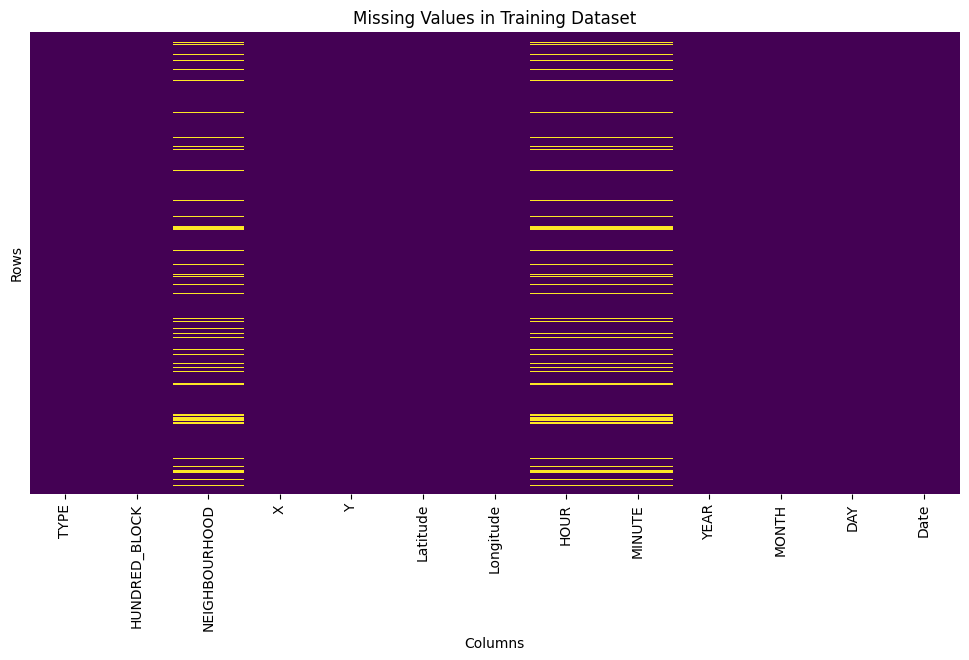

In [42]:
#Visualizing Missing Values using heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.heatmap(train_df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap="viridis")

plt.title("Missing Values in Training Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

###Visualisation of missing value percentage bar-chart

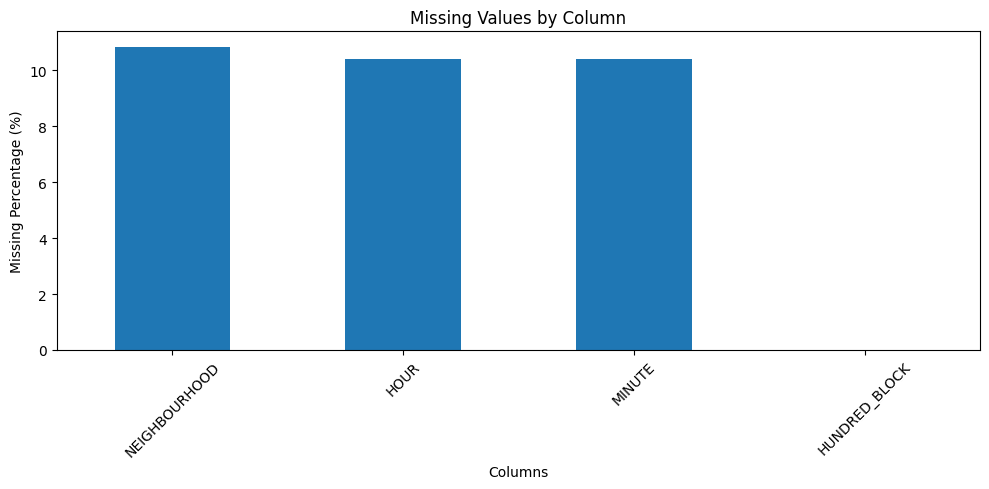

In [43]:
missing_percentage = (
    train_df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage > 0]

plt.figure(figsize=(10, 5))

missing_percentage.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

###Test Dataset Visualization

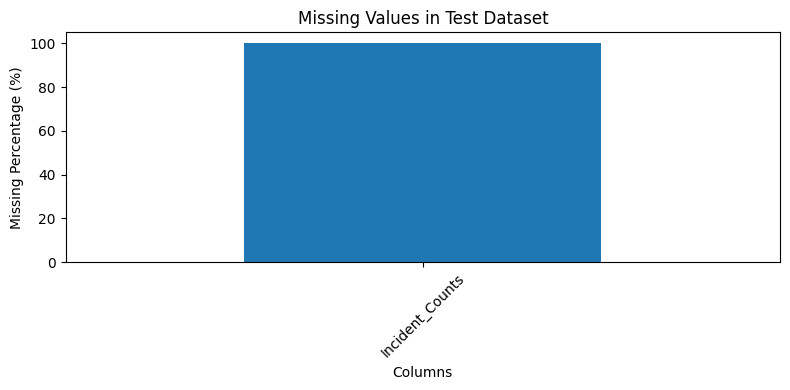

In [44]:
test_missing_percentage = (
    test_df.isnull().mean() * 100
).sort_values(ascending=False)

test_missing_percentage = test_missing_percentage[test_missing_percentage > 0]

plt.figure(figsize=(8, 4))

test_missing_percentage.plot(kind="bar")

plt.title("Missing Values in Test Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### What did you know about your dataset?


The dataset contains historical crime incident records used to analyze and forecast monthly crime activity.

* The training dataset contains **474,565 crime incident records and 13 features**.
* The data covers the period from **1999 to 2011**.
* The dataset includes crime-related attributes such as **crime type, location, neighborhood, geographical coordinates, hour, minute, year, month, day and date**.
* The major categorical variables include **TYPE, HUNDRED_BLOCK and NEIGHBOURHOOD**.
* The geographical variables **Latitude and Longitude** provide information about the spatial distribution of crime incidents.
* The temporal variables such as **YEAR, MONTH, DAY, HOUR and MINUTE** allow us to identify seasonal, monthly and time-of-day patterns.
* The target for our forecasting analysis is the **monthly number of crime incidents**, aggregated from the individual crime records.
* After aggregation, the dataset contains **1,404 monthly crime-category observations**, which are used for time-series analysis and forecasting.
* The test dataset contains **162 records**, covering the later period **2012–2013**, and is used for prediction/evaluation.
* The dataset contains **9 major crime categories** represented in the forecasting data.
* Duplicate and missing-value checks were performed during the initial data-quality analysis before proceeding with feature engineering and modeling.
* The dataset is primarily suitable for **time-series forecasting and crime pattern analysis**, with temporal, geographical and categorical information that can support resource and patrol planning.


In [45]:
# Create monthly crime counts from the raw training data

monthly_counts = (
    train_df
    .groupby(['YEAR', 'MONTH', 'TYPE'])
    .size()
    .reset_index(name='Incident_Counts')
)

print("Monthly dataset shape:", monthly_counts.shape)

display(monthly_counts.head(20))

Monthly dataset shape: (1404, 4)


,YEAR,MONTH,TYPE,Incident_Counts
0,1999,1,Break and Enter Commercial,303
1,1999,1,Break and Enter Residential/Other,644
2,1999,1,Mischief,551
3,1999,1,Offence Against a Person,338
4,1999,1,Other Theft,247
5,1999,1,Theft from Vehicle,1438
6,1999,1,Theft of Bicycle,96
7,1999,1,Theft of Vehicle,640
8,1999,1,Vehicle Collision or Pedestrian Struck (with I...,139
9,1999,2,Break and Enter Commercial,254


In [46]:
print("Year range:",
      monthly_counts['YEAR'].min(),
      "to",
      monthly_counts['YEAR'].max())

print("Crime types:", monthly_counts['TYPE'].nunique())

print("\nCrime types:")
print(monthly_counts['TYPE'].unique())

Year range: 1999 to 2011
Crime types: 9

Crime types:
['Break and Enter Commercial' 'Break and Enter Residential/Other'
 'Mischief' 'Offence Against a Person' 'Other Theft' 'Theft from Vehicle'
 'Theft of Bicycle' 'Theft of Vehicle'
 'Vehicle Collision or Pedestrian Struck (with Injury)']


In [47]:
# Check the Test dataset
print("Test shape:", test_df.shape)

display(test_df.head(20))

print("\nTest year/month range:")
print(test_df['YEAR'].min(), "to", test_df['YEAR'].max())

print("\nTest crime types:")
print(test_df['TYPE'].unique())

print("\nNumber of test crime types:")
print(test_df['TYPE'].nunique())

Test shape: (162, 4)


,YEAR,MONTH,TYPE,Incident_Counts
0,2013,6,Vehicle Collision or Pedestrian Struck (with I...,NaN
1,2013,6,Theft of Vehicle,NaN
2,2013,6,Theft of Bicycle,NaN
3,2013,6,Theft from Vehicle,NaN
4,2013,6,Other Theft,NaN
5,2013,6,Offence Against a Person,NaN
6,2013,6,Mischief,NaN
7,2013,6,Break and Enter Residential/Other,NaN
8,2013,6,Break and Enter Commercial,NaN
9,2013,5,Vehicle Collision or Pedestrian Struck (with I...,NaN



Test year/month range:
2012 to 2013

Test crime types:
['Vehicle Collision or Pedestrian Struck (with Injury)' 'Theft of Vehicle'
 'Theft of Bicycle' 'Theft from Vehicle' 'Other Theft'
 'Offence Against a Person' 'Mischief' 'Break and Enter Residential/Other'
 'Break and Enter Commercial']

Number of test crime types:
9


In [48]:
# Check whether every Test combination exists as a crime type
print("Training crime types:")
print(sorted(monthly_counts['TYPE'].unique()))

print("\nTest crime types:")
print(sorted(test_df['TYPE'].unique()))

Training crime types:
['Break and Enter Commercial', 'Break and Enter Residential/Other', 'Mischief', 'Offence Against a Person', 'Other Theft', 'Theft from Vehicle', 'Theft of Bicycle', 'Theft of Vehicle', 'Vehicle Collision or Pedestrian Struck (with Injury)']

Test crime types:
['Break and Enter Commercial', 'Break and Enter Residential/Other', 'Mischief', 'Offence Against a Person', 'Other Theft', 'Theft from Vehicle', 'Theft of Bicycle', 'Theft of Vehicle', 'Vehicle Collision or Pedestrian Struck (with Injury)']


In [49]:
test_months = (
    test_df[['YEAR', 'MONTH']]
    .drop_duplicates()
    .sort_values(['YEAR', 'MONTH'])
)

print("Number of months:", len(test_months))
display(test_months)

Number of months: 18


,YEAR,MONTH
153,2012,1
144,2012,2
135,2012,3
126,2012,4
117,2012,5
108,2012,6
99,2012,7
90,2012,8
81,2012,9
72,2012,10


In [50]:
expected = 13 * 12 * 9

print("Expected training combinations:", expected)
print("Actual training combinations:", len(monthly_counts))

print(
    "Missing combinations:",
    expected - len(monthly_counts)
)

Expected training combinations: 1404
Actual training combinations: 1404
Missing combinations: 0


In [51]:
monthly_counts['Date'] = pd.to_datetime(
    monthly_counts['YEAR'].astype(str) + '-' +
    monthly_counts['MONTH'].astype(str) + '-01'
)

monthly_counts = monthly_counts.sort_values(
    ['TYPE', 'Date']
).reset_index(drop=True)

display(monthly_counts.head(15))

,YEAR,MONTH,TYPE,Incident_Counts,Date
0,1999,1,Break and Enter Commercial,303,1999-01-01
1,1999,2,Break and Enter Commercial,254,1999-02-01
2,1999,3,Break and Enter Commercial,292,1999-03-01
3,1999,4,Break and Enter Commercial,266,1999-04-01
4,1999,5,Break and Enter Commercial,291,1999-05-01
5,1999,6,Break and Enter Commercial,306,1999-06-01
6,1999,7,Break and Enter Commercial,252,1999-07-01
7,1999,8,Break and Enter Commercial,241,1999-08-01
8,1999,9,Break and Enter Commercial,209,1999-09-01
9,1999,10,Break and Enter Commercial,306,1999-10-01


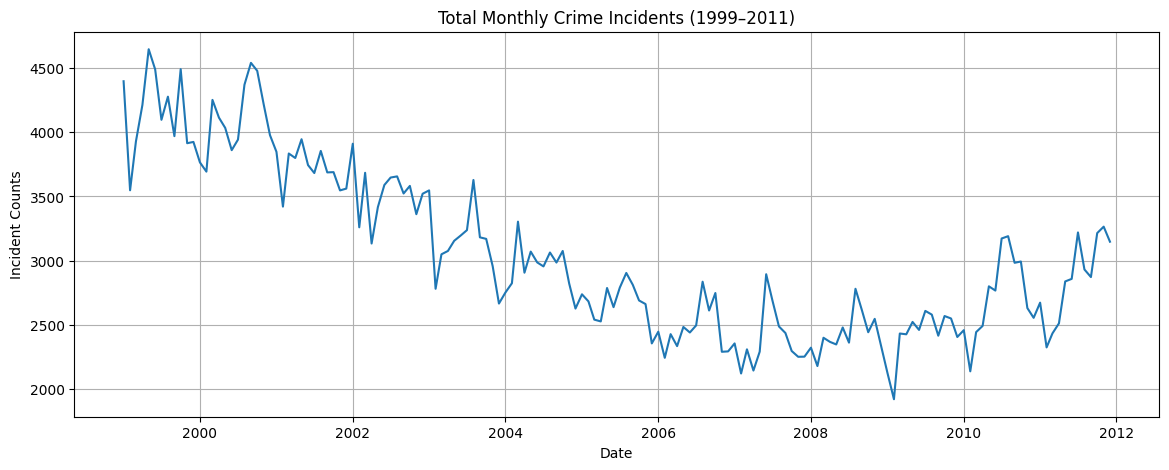

In [52]:
import matplotlib.pyplot as plt

# Overall monthly crime counts
overall_monthly = (
    monthly_counts
    .groupby('Date')['Incident_Counts']
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(
    overall_monthly['Date'],
    overall_monthly['Incident_Counts']
)

plt.title('Total Monthly Crime Incidents (1999–2011)')
plt.xlabel('Date')
plt.ylabel('Incident Counts')
plt.grid(True)
plt.show()

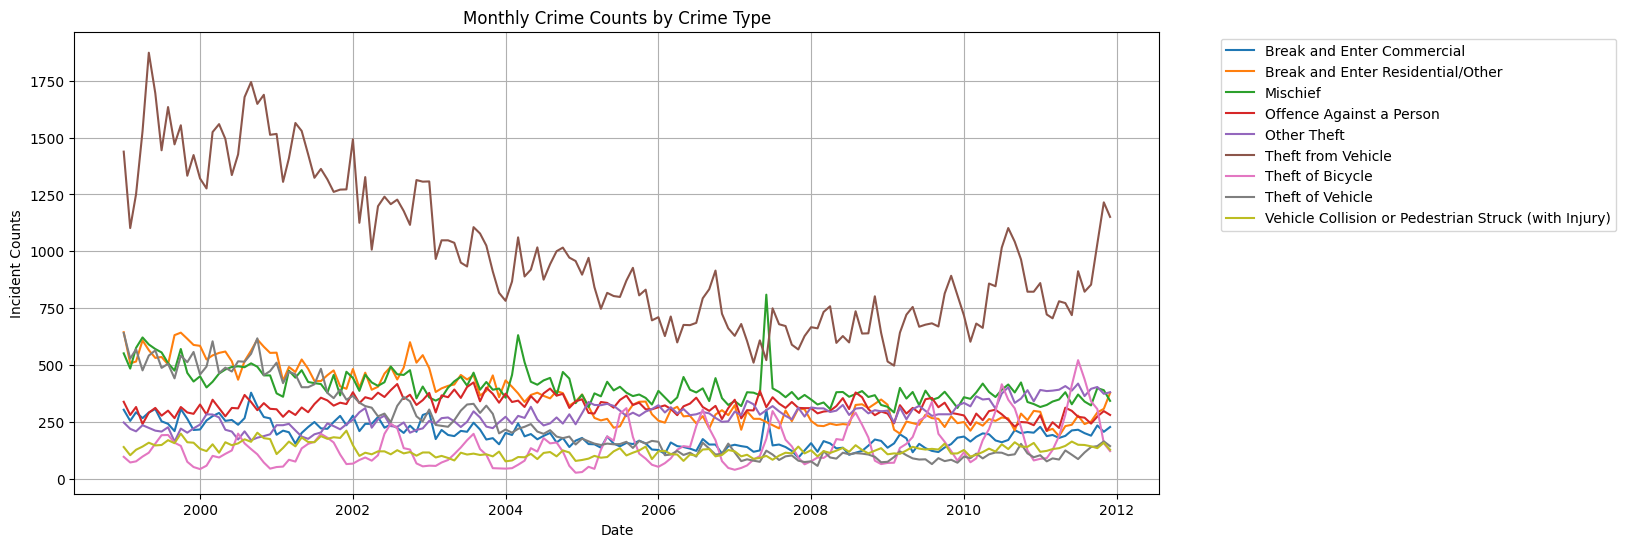

In [53]:
plt.figure(figsize=(14, 6))

for crime_type in monthly_counts['TYPE'].unique():
    data = monthly_counts[monthly_counts['TYPE'] == crime_type]
    plt.plot(
        data['Date'],
        data['Incident_Counts'],
        label=crime_type
    )

plt.title('Monthly Crime Counts by Crime Type')
plt.xlabel('Date')
plt.ylabel('Incident Counts')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

In [54]:
# Average incident count for each calendar month
seasonality = (
    monthly_counts
    .groupby(['MONTH', 'TYPE'])['Incident_Counts']
    .mean()
    .reset_index()
)

display(seasonality.head(20))

,MONTH,TYPE,Incident_Counts
0,1,Break and Enter Commercial,203.000000
1,1,Break and Enter Residential/Other,404.000000
2,1,Mischief,381.923077
3,1,Offence Against a Person,327.923077
4,1,Other Theft,288.153846
5,1,Theft from Vehicle,988.384615
6,1,Theft of Bicycle,63.384615
7,1,Theft of Vehicle,253.461538
8,1,Vehicle Collision or Pedestrian Struck (with I...,116.461538
9,2,Break and Enter Commercial,178.692308


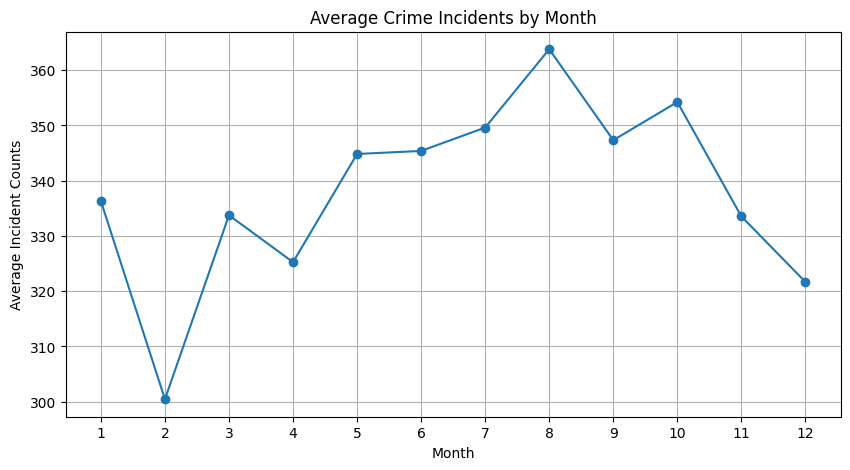

In [55]:
monthly_seasonality = (
    monthly_counts
    .groupby('MONTH')['Incident_Counts']
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_seasonality.index,
    monthly_seasonality.values,
    marker='o'
)

plt.title('Average Crime Incidents by Month')
plt.xlabel('Month')
plt.ylabel('Average Incident Counts')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [56]:
# Calculate the average number of incidents for each month
# separately for each crime type.

seasonality = (
    monthly_counts
    .groupby(['TYPE', 'MONTH'])['Incident_Counts']
    .mean()
    .reset_index()
)

print("Shape:", seasonality.shape)

display(seasonality.head(20))

Shape: (108, 3)


,TYPE,MONTH,Incident_Counts
0,Break and Enter Commercial,1,203.000000
1,Break and Enter Commercial,2,178.692308
2,Break and Enter Commercial,3,204.153846
3,Break and Enter Commercial,4,187.307692
4,Break and Enter Commercial,5,190.769231
5,Break and Enter Commercial,6,204.307692
6,Break and Enter Commercial,7,184.153846
7,Break and Enter Commercial,8,191.153846
8,Break and Enter Commercial,9,189.538462
9,Break and Enter Commercial,10,200.923077


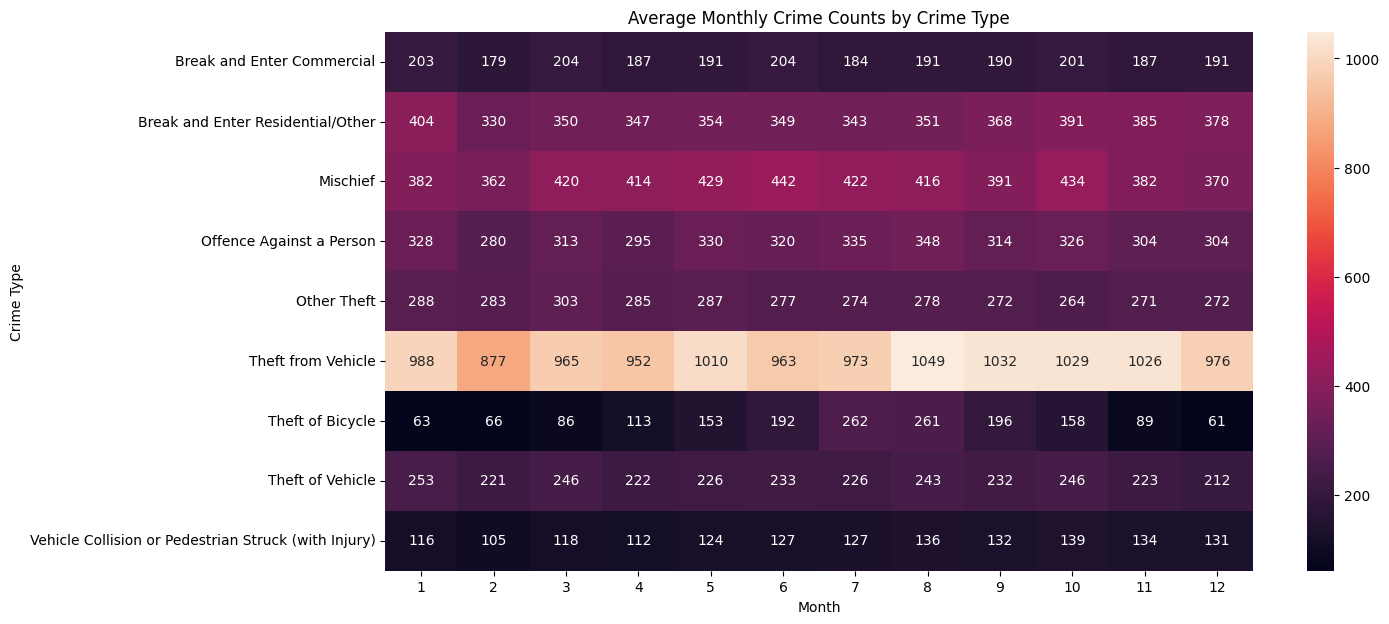

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

# Convert the data into a table:
# rows = crime types
# columns = months
# values = average incident count

seasonality_pivot = seasonality.pivot(
    index='TYPE',
    columns='MONTH',
    values='Incident_Counts'
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    seasonality_pivot,
    annot=True,
    fmt='.0f'
)

plt.title('Average Monthly Crime Counts by Crime Type')
plt.xlabel('Month')
plt.ylabel('Crime Type')

plt.show()

In [58]:
# See which variables currently exist
overall_monthly.head()

,Date,Incident_Counts
0,1999-01-01,4396
1,1999-02-01,3548
2,1999-03-01,3928
3,1999-04-01,4212
4,1999-05-01,4645


In [59]:
overall_monthly.head()

,Date,Incident_Counts
0,1999-01-01,4396
1,1999-02-01,3548
2,1999-03-01,3928
3,1999-04-01,4212
4,1999-05-01,4645


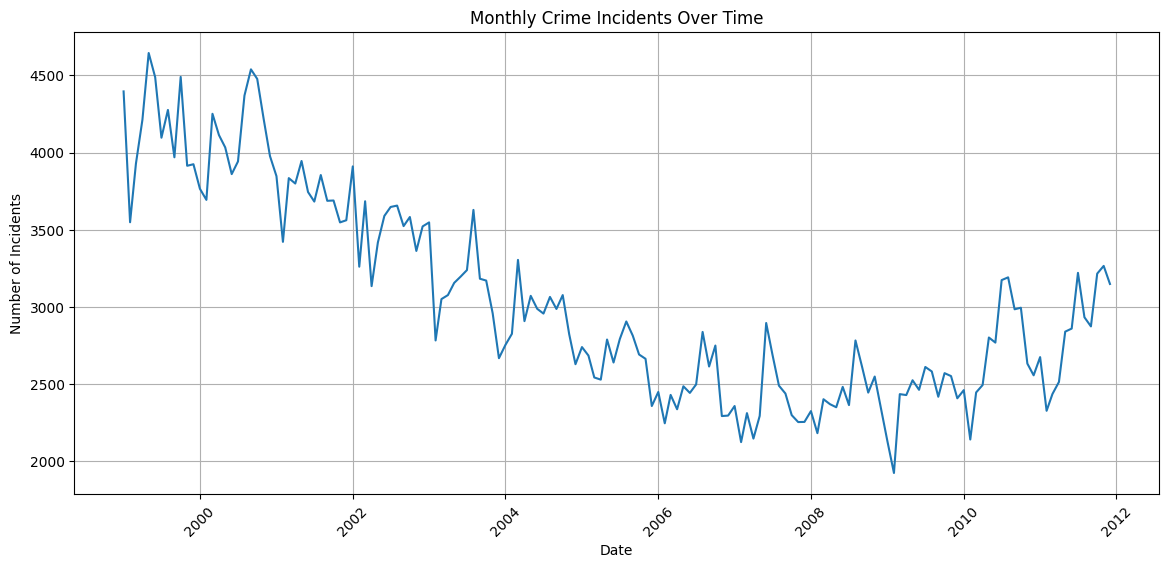

In [60]:
plt.figure(figsize=(14, 6))

plt.plot(
    overall_monthly["Date"],
    overall_monthly["Incident_Counts"]
)

plt.title("Monthly Crime Incidents Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [61]:
print("overall_monthly:")
print(overall_monthly.shape)
print(overall_monthly.head())

print("\ntrain_df:")
print(train_df.shape)
print(train_df.head())

print("\ntest_df:")
print(test_df.shape)
print(test_df.head())

print("\ntest_months:")
print(test_months)

overall_monthly:
(156, 2)
        Date  Incident_Counts
0 1999-01-01             4396
1 1999-02-01             3548
2 1999-03-01             3928
3 1999-04-01             4212
4 1999-05-01             4645

train_df:
(474565, 13)
          TYPE     HUNDRED_BLOCK NEIGHBOURHOOD         X           Y  \
0  Other Theft  9XX TERMINAL AVE    Strathcona  493906.5  5457452.47   
1  Other Theft  9XX TERMINAL AVE    Strathcona  493906.5  5457452.47   
2  Other Theft  9XX TERMINAL AVE    Strathcona  493906.5  5457452.47   
3  Other Theft  9XX TERMINAL AVE    Strathcona  493906.5  5457452.47   
4  Other Theft  9XX TERMINAL AVE    Strathcona  493906.5  5457452.47   

    Latitude   Longitude  HOUR  MINUTE  YEAR  MONTH  DAY       Date  
0  49.269802 -123.083763  16.0    15.0  1999      5   12 1999-05-12  
1  49.269802 -123.083763  15.0    20.0  1999      5    7 1999-05-07  
2  49.269802 -123.083763  16.0    40.0  1999      4   23 1999-04-23  
3  49.269802 -123.083763  11.0    15.0  1999      4   20 

In [62]:
# Create a clean monthly time series for forecasting

ts = overall_monthly.copy()

ts['Date'] = pd.to_datetime(ts['Date'])

ts = ts.sort_values('Date')

ts = ts.set_index('Date')['Incident_Counts']

print(ts.head())
print("\nStart:", ts.index.min())
print("End:", ts.index.max())
print("Number of months:", len(ts))

Date
1999-01-01    4396
1999-02-01    3548
1999-03-01    3928
1999-04-01    4212
1999-05-01    4645
Name: Incident_Counts, dtype: int64

Start: 1999-01-01 00:00:00
End: 2011-12-01 00:00:00
Number of months: 156


In [63]:
# Seasonal-naive forecast using the value from 12 months earlier

seasonal_naive = ts.shift(12)

seasonal_naive.head(15)

,Incident_Counts
Date,
1999-01-01,NaN
1999-02-01,NaN
1999-03-01,NaN
1999-04-01,NaN
1999-05-01,NaN
1999-06-01,NaN
1999-07-01,NaN
1999-08-01,NaN
1999-09-01,NaN


In [64]:
# Use the final 12 historical months as the validation period

actual = ts.iloc[-12:]

predicted = seasonal_naive.iloc[-12:]

print("Actual values:")
print(actual)

print("\nSeasonal-naive predictions:")
print(predicted)

Actual values:
Date
2011-01-01    2674
2011-02-01    2326
2011-03-01    2435
2011-04-01    2513
2011-05-01    2839
2011-06-01    2859
2011-07-01    3220
2011-08-01    2932
2011-09-01    2873
2011-10-01    3215
2011-11-01    3265
2011-12-01    3148
Name: Incident_Counts, dtype: int64

Seasonal-naive predictions:
Date
2011-01-01    2460.0
2011-02-01    2140.0
2011-03-01    2445.0
2011-04-01    2493.0
2011-05-01    2801.0
2011-06-01    2768.0
2011-07-01    3173.0
2011-08-01    3191.0
2011-09-01    2984.0
2011-10-01    2994.0
2011-11-01    2632.0
2011-12-01    2556.0
Name: Incident_Counts, dtype: float64


In [65]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np

# Remove any missing values
comparison = pd.DataFrame({
    'Actual': actual,
    'Predicted': predicted
}).dropna()

# Calculate metrics
mae = mean_absolute_error(
    comparison['Actual'],
    comparison['Predicted']
)

rmse = np.sqrt(
    mean_squared_error(
        comparison['Actual'],
        comparison['Predicted']
    )
)

mape = mean_absolute_percentage_error(
    comparison['Actual'],
    comparison['Predicted']
) * 100

r2 = r2_score(
    comparison['Actual'],
    comparison['Predicted']
)

print("Seasonal Naive Baseline")
print("-----------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")

Seasonal Naive Baseline
-----------------------
MAE  : 201.83
RMSE : 284.64
MAPE : 6.75%
R²   : 0.1390


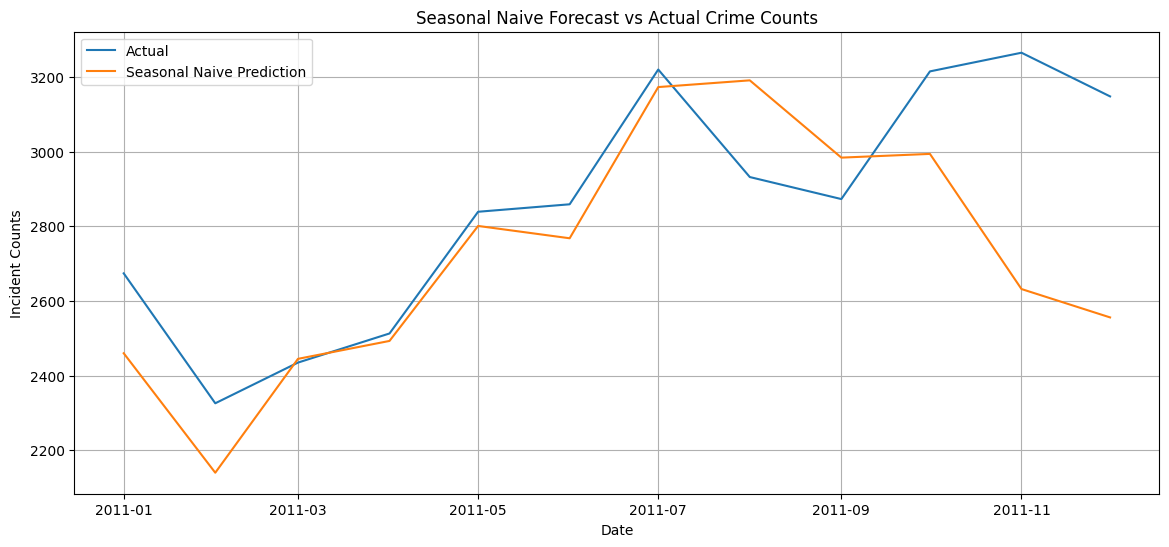

In [66]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparison.index,
    comparison['Actual'],
    label='Actual'
)

plt.plot(
    comparison.index,
    comparison['Predicted'],
    label='Seasonal Naive Prediction'
)

plt.title('Seasonal Naive Forecast vs Actual Crime Counts')
plt.xlabel('Date')
plt.ylabel('Incident Counts')
plt.legend()
plt.grid(True)

plt.show()

In [67]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Training data: 1999-2010
train_ts = ts.loc[:'2010-12-01']

# Validation data: 2011
val_ts = ts.loc['2011-01-01':'2011-12-01']

print("Training observations:", len(train_ts))
print("Validation observations:", len(val_ts))

# Build SARIMA model
sarima_model = SARIMAX(
    train_ts,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

# Forecast 12 months
sarima_forecast = sarima_result.forecast(steps=12)

# Evaluation
sarima_mae = mean_absolute_error(
    val_ts,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        val_ts,
        sarima_forecast
    )
)

sarima_mape = mean_absolute_percentage_error(
    val_ts,
    sarima_forecast
) * 100

sarima_r2 = r2_score(
    val_ts,
    sarima_forecast
)

print("\nSARIMA Results")
print("-----------------------")
print(f"MAE  : {sarima_mae:.2f}")
print(f"RMSE : {sarima_rmse:.2f}")
print(f"MAPE : {sarima_mape:.2f}%")
print(f"R²   : {sarima_r2:.4f}")

Training observations: 144
Validation observations: 12


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)



SARIMA Results
-----------------------
MAE  : 216.89
RMSE : 294.36
MAPE : 7.17%
R²   : 0.0792


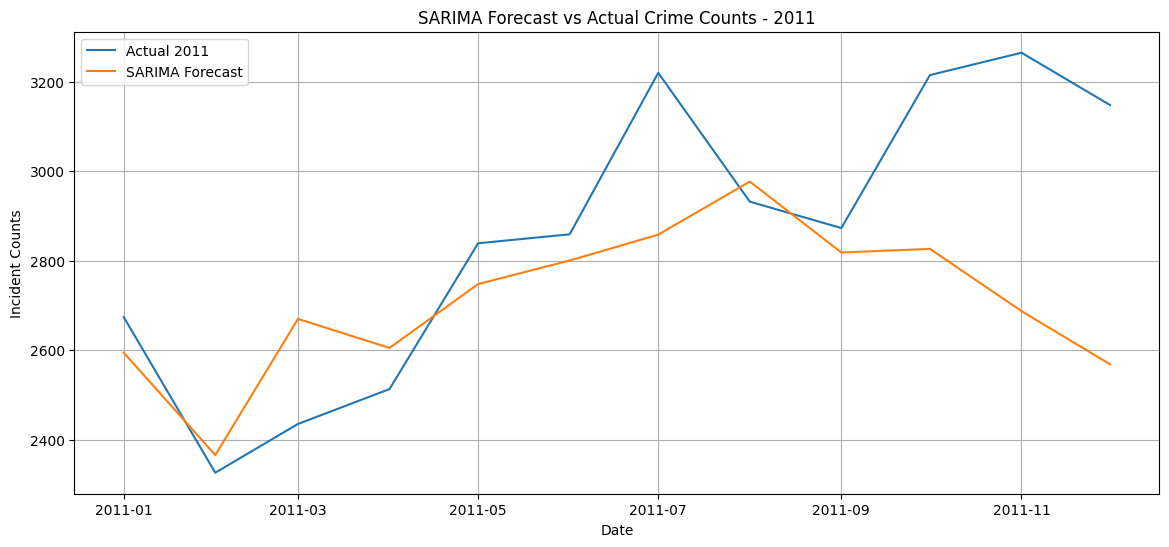

In [68]:
plt.figure(figsize=(14, 6))

plt.plot(
    val_ts.index,
    val_ts.values,
    label='Actual 2011'
)

plt.plot(
    val_ts.index,
    sarima_forecast.values,
    label='SARIMA Forecast'
)

plt.title('SARIMA Forecast vs Actual Crime Counts - 2011')
plt.xlabel('Date')
plt.ylabel('Incident Counts')
plt.legend()
plt.grid(True)
plt.show()

In [69]:
xgb_df = pd.DataFrame({
    'Incident_Counts': ts
})

# Previous month values
xgb_df['lag_1'] = xgb_df['Incident_Counts'].shift(1)
xgb_df['lag_2'] = xgb_df['Incident_Counts'].shift(2)
xgb_df['lag_3'] = xgb_df['Incident_Counts'].shift(3)

# Longer-term lags
xgb_df['lag_6'] = xgb_df['Incident_Counts'].shift(6)
xgb_df['lag_12'] = xgb_df['Incident_Counts'].shift(12)

# Rolling averages using only previous observations
xgb_df['rolling_mean_3'] = (
    xgb_df['Incident_Counts']
    .shift(1)
    .rolling(3)
    .mean()
)

xgb_df['rolling_mean_6'] = (
    xgb_df['Incident_Counts']
    .shift(1)
    .rolling(6)
    .mean()
)

xgb_df['rolling_mean_12'] = (
    xgb_df['Incident_Counts']
    .shift(1)
    .rolling(12)
    .mean()
)

# Calendar features
xgb_df['month'] = xgb_df.index.month
xgb_df['year'] = xgb_df.index.year

# Remove rows where lag values are unavailable
xgb_df = xgb_df.dropna()

print("XGBoost dataset shape:", xgb_df.shape)

display(xgb_df.head())

XGBoost dataset shape: (144, 11)


,Incident_Counts,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,month,year
Date,,,,,,,,,,,
2000-01-01,3765,3924.0,3914.0,4490.0,4096.0,4396.0,4109.333333,4111.500000,4157.166667,1,2000
2000-02-01,3693,3765.0,3924.0,3914.0,4276.0,3548.0,3867.666667,4056.333333,4104.583333,2,2000
2000-03-01,4251,3693.0,3765.0,3924.0,3969.0,3928.0,3794.000000,3959.166667,4116.666667,3,2000
2000-04-01,4113,4251.0,3693.0,3765.0,4490.0,4212.0,3903.000000,4006.166667,4143.583333,4,2000
2000-05-01,4033,4113.0,4251.0,3693.0,3914.0,4645.0,4019.000000,3943.333333,4135.333333,5,2000


In [70]:
# Features used by XGBoost
features = [
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_6',
    'lag_12',
    'rolling_mean_3',
    'rolling_mean_6',
    'rolling_mean_12',
    'month',
    'year'
]

X_train = xgb_df.loc[:'2010-12-01', features]
y_train = xgb_df.loc[:'2010-12-01', 'Incident_Counts']

X_val = xgb_df.loc['2011-01-01':'2011-12-01', features]
y_val = xgb_df.loc['2011-01-01':'2011-12-01', 'Incident_Counts']

print("Training X shape:", X_train.shape)
print("Training y shape:", y_train.shape)

print("Validation X shape:", X_val.shape)
print("Validation y shape:", y_val.shape)

Training X shape: (132, 10)
Training y shape: (132,)
Validation X shape: (12, 10)
Validation y shape: (12,)


In [71]:
from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost model training completed successfully.")

XGBoost model training completed successfully.


In [72]:
# Generate predictions for the 2011 validation period
xgb_predictions = xgb_model.predict(X_val)

# Calculate evaluation metrics
xgb_mae = mean_absolute_error(
    y_val,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        xgb_predictions
    )
)

xgb_mape = mean_absolute_percentage_error(
    y_val,
    xgb_predictions
) * 100

xgb_r2 = r2_score(
    y_val,
    xgb_predictions
)

print("XGBoost Results")
print("-----------------------")
print(f"MAE  : {xgb_mae:.2f}")
print(f"RMSE : {xgb_rmse:.2f}")
print(f"MAPE : {xgb_mape:.2f}%")
print(f"R²   : {xgb_r2:.4f}")

XGBoost Results
-----------------------
MAE  : 153.04
RMSE : 190.83
MAPE : 5.12%
R²   : 0.6130


In [73]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from xgboost import XGBRegressor

# TimeSeriesSplit preserves the chronological order of the data.
# This is important because future observations should not be used
# to train a model for earlier observations.
tscv = TimeSeriesSplit(n_splits=5)

# Create the base XGBoost model
xgb_tuning_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42
)

# Define the hyperparameters and values to test
param_grid = {
    'n_estimators': [200, 300, 400],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# GridSearchCV tests different combinations of parameters
# using TimeSeriesSplit cross-validation.
grid_search = GridSearchCV(
    estimator=xgb_tuning_model,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Perform hyperparameter optimization
grid_search.fit(X_train, y_train)

# Get the best model
best_xgb_model = grid_search.best_estimator_

print("Hyperparameter tuning completed successfully.")
print("\nBest Parameters:")
print(grid_search.best_params_)

Hyperparameter tuning completed successfully.

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}


In [74]:
model_comparison = pd.DataFrame({
    'Model': [
        'Seasonal Naive',
        'SARIMA',
        'XGBoost'
    ],
    'MAE': [
        201.83,
        216.89,
        153.04
    ],
    'RMSE': [
        284.64,
        294.36,
        190.83
    ],
    'MAPE (%)': [
        6.75,
        7.17,
        5.12
    ],
    'R²': [
        0.1390,
        0.0792,
        0.6130
    ]
})

display(model_comparison)

,Model,MAE,RMSE,MAPE (%),R²
0,Seasonal Naive,201.83,284.64,6.75,0.1390
1,SARIMA,216.89,294.36,7.17,0.0792
2,XGBoost,153.04,190.83,5.12,0.6130


In [75]:
# Use all available data from 1999 to 2011
X_final = xgb_df[features]
y_final = xgb_df['Incident_Counts']

print("Final training X shape:", X_final.shape)
print("Final training y shape:", y_final.shape)

Final training X shape: (144, 10)
Final training y shape: (144,)


In [76]:
# Create the final XGBoost model
final_xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

# Train on all available historical data
final_xgb_model.fit(X_final, y_final)

print("Final XGBoost model trained successfully.")

Final XGBoost model trained successfully.


In [77]:
# Copy historical monthly crime counts
history = ts.copy()

# Store future predictions
future_predictions = []

# Generate forecasts month by month
future_dates = pd.date_range(
    start='2012-01-01',
    periods=12,
    freq='MS'
)

for date in future_dates:

    # Create features for the current month
    lag_1 = history.iloc[-1]
    lag_2 = history.iloc[-2]
    lag_3 = history.iloc[-3]
    lag_6 = history.iloc[-6]
    lag_12 = history.iloc[-12]

    rolling_mean_3 = history.iloc[-3:].mean()
    rolling_mean_6 = history.iloc[-6:].mean()
    rolling_mean_12 = history.iloc[-12:].mean()

    month = date.month
    year = date.year

    # Create one-row feature DataFrame
    future_features = pd.DataFrame([{
        'lag_1': lag_1,
        'lag_2': lag_2,
        'lag_3': lag_3,
        'lag_6': lag_6,
        'lag_12': lag_12,
        'rolling_mean_3': rolling_mean_3,
        'rolling_mean_6': rolling_mean_6,
        'rolling_mean_12': rolling_mean_12,
        'month': month,
        'year': year
    }])

    # Predict current month
    prediction = final_xgb_model.predict(future_features)[0]

    # Store prediction
    future_predictions.append(prediction)

    # Add prediction to history so it can be used
    # for the next month's forecast
    history.loc[date] = prediction

# Create final forecast DataFrame
forecast_2012 = pd.DataFrame({
    'Date': future_dates,
    'Forecasted_Incident_Counts': future_predictions
})

display(forecast_2012)

,Date,Forecasted_Incident_Counts
0,2012-01-01,3102.612793
1,2012-02-01,2930.133301
2,2012-03-01,3010.689209
3,2012-04-01,3032.681396
4,2012-05-01,3113.815674
5,2012-06-01,3135.345459
6,2012-07-01,3148.621826
7,2012-08-01,3210.783203
8,2012-09-01,3198.295166
9,2012-10-01,3145.927490


In [78]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': final_xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(feature_importance)

,Feature,Importance
7,rolling_mean_12,0.360302
4,lag_12,0.287218
0,lag_1,0.129893
9,year,0.108028
1,lag_2,0.035409
5,rolling_mean_3,0.024710
6,rolling_mean_6,0.018924
8,month,0.017833
2,lag_3,0.010372
3,lag_6,0.007310


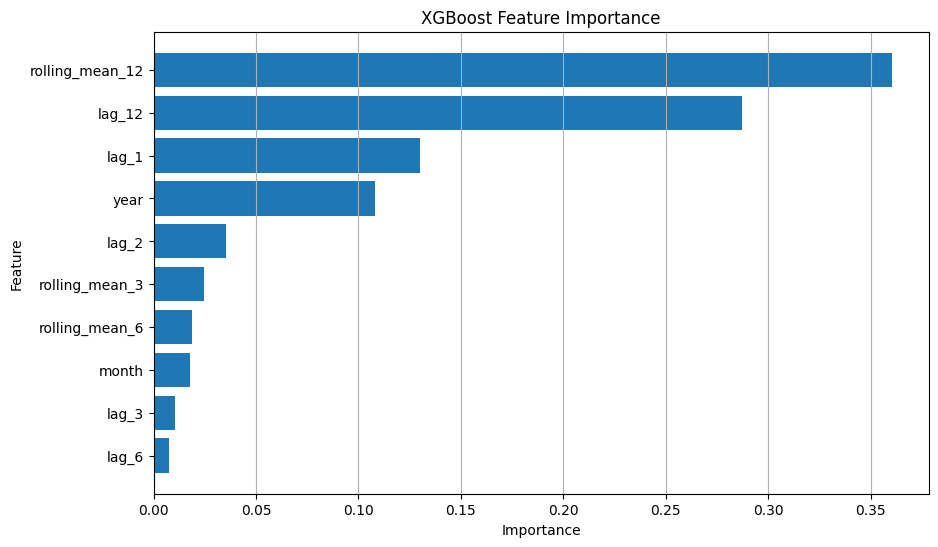

In [79]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.gca().invert_yaxis()

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(axis='x')

plt.show()

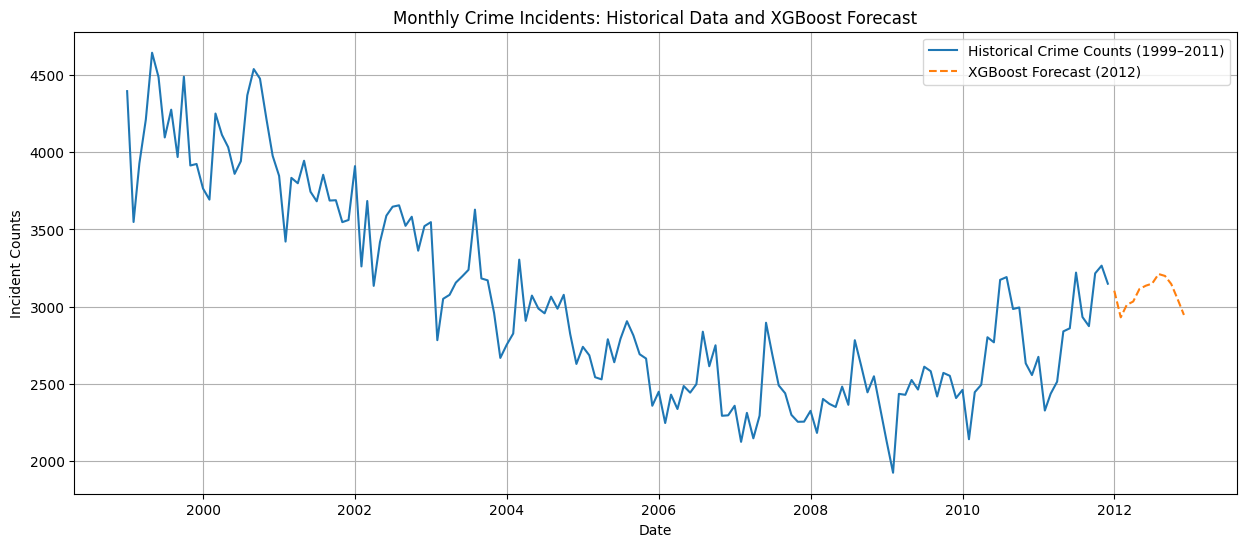

In [80]:
# Combine historical data with the 2012 forecast

plt.figure(figsize=(15, 6))

# Historical crime counts: 1999–2011
plt.plot(
    overall_monthly['Date'],
    overall_monthly['Incident_Counts'],
    label='Historical Crime Counts (1999–2011)'
)

# XGBoost forecast: 2012
plt.plot(
    forecast_2012['Date'],
    forecast_2012['Forecasted_Incident_Counts'],
    label='XGBoost Forecast (2012)',
    linestyle='--'
)

plt.title('Monthly Crime Incidents: Historical Data and XGBoost Forecast')
plt.xlabel('Date')
plt.ylabel('Incident Counts')
plt.legend()
plt.grid(True)
plt.show()

In [81]:
 # Correlation between XGBoost features

correlation_matrix = xgb_df[features].corr()

display(correlation_matrix.round(2))

,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,month,year
lag_1,1.00,0.92,0.89,0.82,0.87,0.97,0.93,0.92,0.15,-0.76
lag_2,0.92,1.00,0.92,0.83,0.88,0.98,0.95,0.93,0.15,-0.78
lag_3,0.89,0.92,1.00,0.86,0.86,0.97,0.96,0.93,0.06,-0.79
lag_6,0.82,0.83,0.86,1.00,0.83,0.86,0.94,0.94,-0.18,-0.81
lag_12,0.87,0.88,0.86,0.83,1.00,0.90,0.90,0.94,0.05,-0.86
rolling_mean_3,0.97,0.98,0.97,0.86,0.90,1.00,0.98,0.96,0.12,-0.80
rolling_mean_6,0.93,0.95,0.96,0.94,0.90,0.98,1.00,0.98,0.01,-0.83
rolling_mean_12,0.92,0.93,0.93,0.94,0.94,0.96,0.98,1.00,-0.06,-0.87
month,0.15,0.15,0.06,-0.18,0.05,0.12,0.01,-0.06,1.00,0.00
year,-0.76,-0.78,-0.79,-0.81,-0.86,-0.80,-0.83,-0.87,0.00,1.00


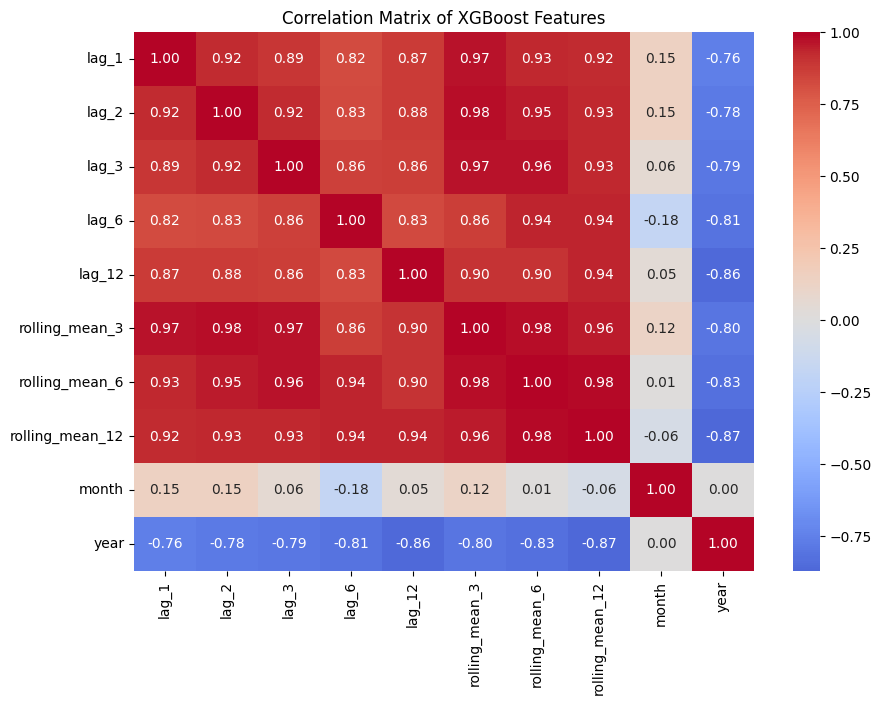

In [82]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of XGBoost Features')
plt.show()

In [83]:
# Find feature pairs with absolute correlation above 0.80

high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:
            high_corr_pairs.append({
                'Feature 1': correlation_matrix.columns[i],
                'Feature 2': correlation_matrix.columns[j],
                'Correlation': round(corr_value, 2)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

display(high_corr_df)

,Feature 1,Feature 2,Correlation
0,lag_1,lag_2,0.92
1,lag_1,lag_3,0.89
2,lag_1,lag_6,0.82
3,lag_1,lag_12,0.87
4,lag_1,rolling_mean_3,0.97
5,lag_1,rolling_mean_6,0.93
6,lag_1,rolling_mean_12,0.92
7,lag_2,lag_3,0.92
8,lag_2,lag_6,0.83
9,lag_2,lag_12,0.88


###**CONCLUSION**

This project developed a machine learning and time-series forecasting solution for analyzing historical crime incident patterns and forecasting future incident counts.
The project involved data exploration, missing-value analysis, duplicate-value analysis, preprocessing, temporal feature engineering, and aggregation of incident-level records into a forecasting dataset. Multiple forecasting approaches, including Seasonal Naive, SARIMA, and XGBoost, were evaluated to understand their performance on the crime-count forecasting problem.
The XGBoost model achieved an MAE of approximately 153.04, RMSE of approximately 190.83, MAPE of approximately 5.12%, and R² of approximately 0.613 on the evaluated dataset. The model benefited from temporal features such as lagged values and rolling statistics, which helped capture historical patterns and seasonality in incident counts.
A Streamlit dashboard was also developed to make the forecasting results easier to explore and interpret. The application allows users to interact with the forecasting results rather than relying only on notebook-based analysis.
Overall, the project demonstrates an end-to-end machine learning workflow covering data preprocessing, time-series feature engineering, model comparison, forecasting, evaluation, and deployment through an interactive application. The system is intended for analytical and forecasting purposes and should not be interpreted as a tool for profiling individuals or predicting individual criminal behavior.
